In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


In [3]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Pixel values normalized")

Pixel values normalized


In [14]:
#for chit  15 you need to add  Dense(64, activation="relu")
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.9248 - loss: 0.2604
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9664 - loss: 0.1145
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.9767 - loss: 0.0792
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9814 - loss: 0.0604
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9853 - loss: 0.0466


In [7]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Testing Accuracy:", accuracy)
print("Testing Accuracy (%):", accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9753 - loss: 0.0825
Testing Accuracy: 0.9753000140190125
Testing Accuracy (%): 97.53000140190125


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


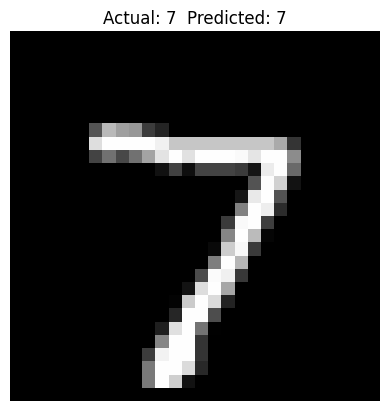

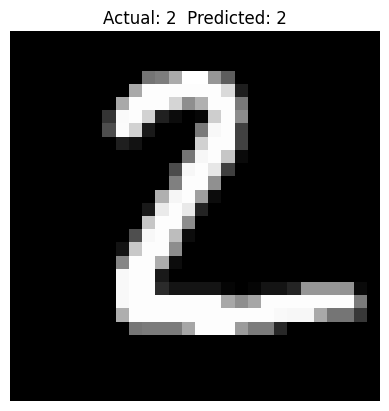

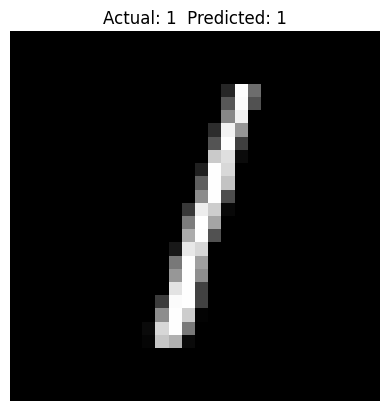

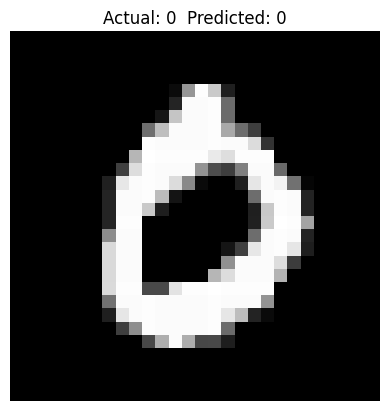

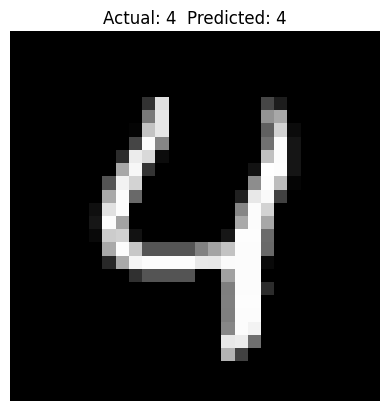

In [8]:
predictions = model.predict(X_test)

for i in range(5):
    predicted = np.argmax(predictions[i])

    plt.imshow(X_test[i], cmap="gray")
    plt.title(f"Actual: {y_test[i]}  Predicted: {predicted}")
    plt.axis("off")
    plt.show()

Actual: 0
Predicted: 0


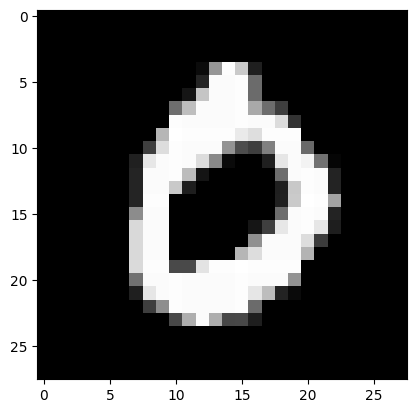

In [13]:
index=3
image=X_test[index]
plt.imshow(image,cmap="gray")

prediction=model.predict(np.array([image]),verbose=0)

print("Actual:",y_test[index])
print("Predicted:", np.argmax(prediction)) 